# Member 2: Empirical MDP, policy iteration and behavior TD baseline

Run Member 1 first. All results here describe the synthetic training MDP, not clinical performance.

In [1]:
import json
import os
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

root = next((path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'main_pipeline.py').is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from the project root or a member folder")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from main_pipeline import load_configs, prepare_data, train_model, evaluate_model

output = Path(os.environ.get('ASS2_OUTPUT_DIR', root)).resolve()
print("Source: synthetic coursework demo; no clinical efficacy claim.")
print("Output:", output)


Source: synthetic coursework demo; no clinical efficacy claim.
Output: C:\Users\ADMIN\Desktop\ass2


## 1. Train using the saved run configuration

Policy evaluation must converge before policy improvement is accepted. Hitting iteration limits raises an error.

In [2]:
trainer = train_model(output)
mdp, pi_solver, td_solver = trainer.mdp, trainer.pi, trainer.td_eval
tr_train = pd.read_csv(output / 'data/trajectories_train.csv')
print("Converged:", pi_solver.converged, "| Iterations:", len(pi_solver.history))
pd.DataFrame(pi_solver.history)


Converged: True | Iterations: 3


,iteration,actions_changed,mean_v,stable
0,1,53,63.888637,False
1,2,8,86.148852,False
2,3,0,86.282364,True


## 2. Inspect empirical action support

Actions below the count threshold are excluded when alternatives exist. If a state has no action meeting the threshold, the most frequent observed action is retained explicitly as a fallback. An unobserved cluster has a placeholder self-loop; it is not evidence of a safe action.

In [3]:
print("Transition tensor:", mdp.transitions.shape)
print("Below-threshold fallback states:", mdp.fallback_states)
print("Unobserved placeholder states:", mdp.unobserved_states)
assert np.allclose(mdp.transitions[mdp.valid_action_mask].sum(axis=1), 1)
pd.DataFrame({'state': range(mdp.n_states), 'allowed_actions': mdp.valid_action_mask[:mdp.n_states].sum(axis=1)})


Transition tensor: (77, 25, 77)
Below-threshold fallback states: [27, 28, 52, 58, 71]
Unobserved placeholder states: []


,state,allowed_actions
0,0,2
1,1,4
2,2,6
3,3,5
4,4,7
...,...,...
70,70,1
71,71,1
72,72,5
73,73,7


## 3. Batch empirical-policy TD(0)

Each iteration averages TD targets for observed state-action pairs. State values weight Q by empirical action frequencies, not uniformly over 25 actions. Training-state means below are not held-out OPE estimates.

In [4]:
print("TD iterations:", td_solver.iterations)
pd.DataFrame({'AI training-state V': pi_solver.V[:mdp.n_states], 'Behavior training-state V': td_solver.get_clinician_state_values()}).describe()


TD iterations: 301


,AI training-state V,Behavior training-state V
count,75.000000,7.500000e+01
mean,86.282364,8.099067e+01
std,27.950691,1.624896e+01
min,0.000000,-4.440892e-16
25%,93.457944,7.848799e+01
50%,95.238095,8.701831e+01
75%,96.515562,9.007334e+01
max,98.765432,9.367681e+01


## 4. Policy iteration convergence

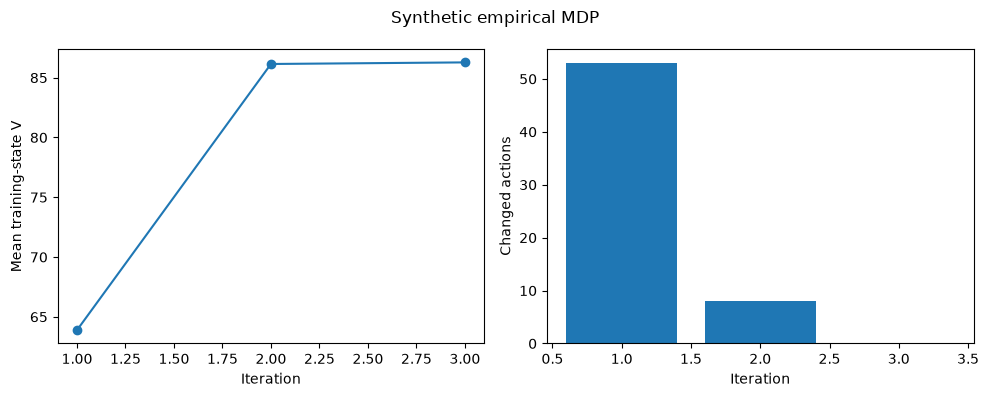

In [5]:
import matplotlib.pyplot as plt
history = pd.DataFrame(pi_solver.history)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history['iteration'], history['mean_v'], marker='o')
axes[0].set(xlabel='Iteration', ylabel='Mean training-state V')
axes[1].bar(history['iteration'], history['actions_changed'])
axes[1].set(xlabel='Iteration', ylabel='Changed actions')
fig.suptitle('Synthetic empirical MDP')
fig.tight_layout()
plt.show()
plt.close(fig)


## 5. Inspect actions and export metadata

In [6]:
policy = trainer.get_policy()
display(pd.DataFrame({'state': range(len(policy)), 'action': policy, 'fluid_bin': policy // 5, 'vaso_bin': policy % 5}).head(15))
metadata = json.loads((output / 'artifacts/ai_policy.json').read_text())
display({key: value for key, value in metadata.items() if key != 'policy'})


,state,action,fluid_bin,vaso_bin
0,0,0,0,0
1,1,15,3,0
2,2,3,0,3
3,3,5,1,0
4,4,0,0,0
5,5,5,1,0
6,6,0,0,0
7,7,15,3,0
8,8,15,3,0
9,9,20,4,0


{'n_states': 75,
 'n_actions': 25,
 'gamma': 0.99,
 'min_action_count': 5,
 'mean_v': 86.2823639633657,
 'td_clinician_mean_v': 80.99066997805647,
 'value_scope': 'Unweighted training-state means, not held-out policy returns',
 'clinician_method': 'Converged batch empirical-policy TD(0)',
 'converged': True,
 'below_threshold_fallback_states': [27, 28, 52, 58, 71],
 'unobserved_self_loop_states': [],
 'history': [{'iteration': 1,
   'actions_changed': 53,
   'mean_v': 63.88863681280313,
   'stable': False},
  {'iteration': 2,
   'actions_changed': 8,
   'mean_v': 86.14885166380783,
   'stable': False},
  {'iteration': 3,
   'actions_changed': 0,
   'mean_v': 86.28236384856497,
   'stable': True}]}